# Data overview and quality checks

**Purpose:** check the quality of the Smart Home Energy Consumption dataset and test whether homes differ enough to be grouped into segments.

**Data:** Kaggle, "Smart Home Energy Consumption" (mexwell), file `smart_home_energy_consumption_large.csv`: 100,000 readings, 500 homes, 10 appliance types. 

**Requires:** pandas, numpy, matplotlib.

**Summary of findings:** the data are technically clean but behave like simulated data. There is no seasonal pattern, household size changes within every home, and differences between homes are no larger than random sampling would produce. The only clear signal is appliance type.

### 1. Load data and structure

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/smart_home_energy_consumption_large.csv")

print("Shape (rows, columns):", df.shape)
print("Columns:", df.columns.tolist())
df.info()

Shape (rows, columns): (100000, 8)
Columns: ['Home ID', 'Appliance Type', 'Energy Consumption (kWh)', 'Time', 'Date', 'Outdoor Temperature (°C)', 'Season', 'Household Size']
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Home ID                   100000 non-null  int64  
 1   Appliance Type            100000 non-null  str    
 2   Energy Consumption (kWh)  100000 non-null  float64
 3   Time                      100000 non-null  str    
 4   Date                      100000 non-null  str    
 5   Outdoor Temperature (°C)  100000 non-null  float64
 6   Season                    100000 non-null  str    
 7   Household Size            100000 non-null  int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 6.1 MB


### 2. Data quality checks

In [2]:
# 1. Missing values per column
print("Missing values:")
print(df.isna().sum())

# 2. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Number of homes, appliance types and seasons
print("\nUnique homes:", df["Home ID"].nunique())

print("\nAppliance types:", df["Appliance Type"].nunique())
print(df["Appliance Type"].value_counts())
print("\nSeasons:")
print(df["Season"].value_counts())

# 4. Energy consumption: range and invalid values
print("\nEnergy consumption summary:")
print(df["Energy Consumption (kWh)"].describe())
print("Readings with kWh <= 0:", (df["Energy Consumption (kWh)"] <= 0).sum())

Missing values:
Home ID                     0
Appliance Type              0
Energy Consumption (kWh)    0
Time                        0
Date                        0
Outdoor Temperature (°C)    0
Season                      0
Household Size              0
dtype: int64

Duplicate rows: 0

Unique homes: 500

Appliance types: 10
Appliance Type
Lights              10201
Dishwasher          10095
Air Conditioning    10067
Heater              10018
Washing Machine      9953
Microwave            9947
Computer             9944
Oven                 9939
Fridge               9931
TV                   9905
Name: count, dtype: int64

Seasons:
Season
Spring    25112
Fall      25026
Summer    24966
Winter    24896
Name: count, dtype: int64

Energy consumption summary:
count    100000.000000
mean          1.499952
std           1.181176
min           0.100000
25%           0.590000
50%           1.230000
75%           1.870000
max           5.000000
Name: Energy Consumption (kWh), dtype: float64
Read

**Findings:**
- 100,000 rows and 8 columns; no missing values and no duplicate rows.
- 500 unique homes and 10 appliance types, with roughly equal numbers of readings (9,905 to 10,201).
- Seasons are evenly distributed (about 25,000 readings each).
- Energy consumption ranges from 0.1 to 5.0 kWh (mean 1.50, median 1.23); no zero or negative values.
- Evenly spread counts and bounded values are early signs of simulated data; sections 4 to 10 test this further.

### 3. Date range and season labels

In [3]:
# Convert Date to datetime and check the covered period
df["Date"] = pd.to_datetime(df["Date"])
print("Date range:", df["Date"].min(), "to", df["Date"].max())

# Check which season is assigned to each month
df["Month"] = df["Date"].dt.month
pd.crosstab(df["Month"], df["Season"])

Date range: 2023-01-01 00:00:00 to 2024-01-01 00:00:00


Season,Fall,Spring,Summer,Winter
Month,,,,
1,0,0,0,8787
2,0,0,0,7670
3,0,0,0,8439
4,0,8312,0,0
5,0,8439,0,0
6,0,8361,0,0
7,0,0,8450,0
8,0,0,8362,0
9,0,0,8154,0


**Findings:**
- The data cover 2023-01-01 to 2024-01-01 (one year plus one day).
- Seasons follow calendar quarters: Winter = Jan to Mar, Spring = Apr to Jun, Summer = Jul to Sep, Fall = Oct to Dec.
- This differs from the meteorological convention (Winter = Dec to Feb), so December is labelled Fall.

### 4. Temperature by month

In [4]:
# Check whether outdoor temperature follows the Season labels

monthly_temp = df.groupby("Month")["Outdoor Temperature (°C)"].mean().round(1)
print(monthly_temp)

Month
1     14.7
2     14.8
3     15.1
4     15.0
5     15.1
6     15.2
7     14.8
8     15.0
9     15.0
10    15.0
11    14.8
12    15.0
Name: Outdoor Temperature (°C), dtype: float64


**Findings:**
- Mean outdoor temperature is almost identical in all months (14.7 to 15.2 °C), so it does not follow a seasonal cycle.
- This is consistent with simulated data, which the mentor has confirmed for this dataset.
- Season is a calendar-quarter label only and does not reflect real weather; it is not used as a segmentation feature.

### 5. Seasonal consumption by appliance

In [5]:
seasonal_use = df.pivot_table(
    index="Appliance Type",
    columns="Season",
    values="Energy Consumption (kWh)",
    aggfunc="mean"
).round(2)
seasonal_use

Season,Fall,Spring,Summer,Winter
Appliance Type,,,,
Air Conditioning,3.47,3.53,3.49,3.52
Computer,1.10,1.11,1.08,1.09
Dishwasher,1.11,1.10,1.10,1.11
Fridge,0.30,0.30,0.30,0.30
Heater,3.48,3.48,3.51,3.47
Lights,1.08,1.09,1.10,1.08
Microwave,1.11,1.12,1.07,1.10
Oven,1.09,1.13,1.09,1.10
TV,1.09,1.10,1.09,1.10


**Findings:**
- Average kWh per appliance is nearly identical across seasons (largest difference about 0.06 kWh, for Air Conditioning).
- Appliances fall into three stable groups: high (Air Conditioning and Heater, about 3.5 kWh), medium (seven appliances, about 1.1 kWh) and low (Fridge, 0.30 kWh).
- Air Conditioning is not higher in Summer and Heater is not higher in Winter, so there is no seasonal pattern.
- Implication: a seasonal ratio is not a useful segmentation feature. The home-level tests in sections 9 and 10 found no structure that seasonal features could add.

### 6. Consumption by household size

In [10]:
household_use = df.groupby("Household Size")["Energy Consumption (kWh)"].agg(["count", "mean"]).round(2)
household_use

,count,mean
Household Size,,
1,20175,1.51
2,19692,1.51
3,20013,1.49
4,20021,1.50
5,20099,1.49


**Findings:**
- Each household size (1 to 5) has about 20,000 readings (19,692 to 20,175).
- Average kWh is nearly identical across sizes (1.49 to 1.51 kWh).
- Household size does not explain differences in consumption in this dataset. 

### 7. Variation between homes

count    500.000
mean       1.500
std        0.080
min        1.278
25%        1.444
50%        1.493
75%        1.555
max        1.755
Name: Energy Consumption (kWh), dtype: float64


<Axes: >

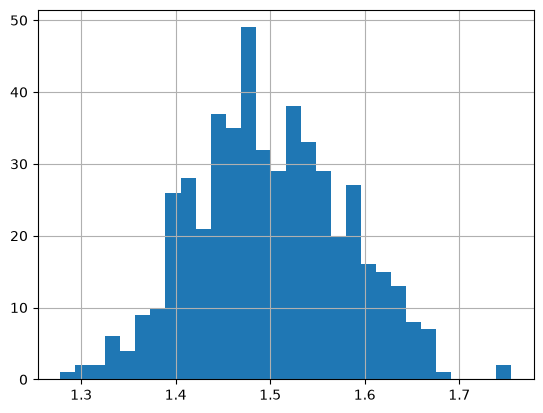

In [6]:
# Variation between homes: average kWh per home
home_mean = df.groupby("Home ID")["Energy Consumption (kWh)"].mean()
print(home_mean.describe().round(3))
home_mean.hist(bins=30)

**Findings:**
- Average kWh per home: mean 1.50, std 0.080, range 1.28 to 1.76.
- The distribution is a single symmetric bell shape with no visible clusters.
- If all homes were identical, sampling noise alone would give a spread of about 1.18 / sqrt(200) = 0.083 (1.18 is the std of a single reading, 200 the average number of readings per home). The observed 0.080 is almost identical.
- Implication: total consumption does not separate homes. This is tested formally with shuffled data in sections 9 and 10.

### 8. Structure per home

In [7]:
rows_per_home = df.groupby("Home ID").size()
print(rows_per_home.describe())

appliances_per_home = df.groupby("Home ID")["Appliance Type"].nunique()
print(appliances_per_home.value_counts())

hs_per_home = df.groupby("Home ID")["Household Size"].nunique()
print("Homes with more than one household size:", (hs_per_home > 1).sum())

print(hs_per_home.value_counts().sort_index())

count    500.000000
mean     200.000000
std       13.885157
min      157.000000
25%      191.000000
50%      200.000000
75%      209.000000
max      245.000000
dtype: float64
Appliance Type
10    500
Name: count, dtype: int64
Homes with more than one household size: 500
Household Size
5    500
Name: count, dtype: int64


**Findings:**
- Each home has between 157 and 245 readings (mean 200).
- All 500 homes have all 10 appliance types (about 20 readings per appliance per home).
- Household Size varies within every home (500 of 500 homes have more than one value).
- Implication: Household Size is not a home-level attribute in this dataset and cannot define peer groups.

### 9. Permutation test on home-level mean kWh

In [8]:
rng = np.random.default_rng(42)
real_std = home_mean.std()

shuffled_stds = []
for _ in range(200):
    shuffled_ids = rng.permutation(df["Home ID"].values)
    shuffled_mean = df["Energy Consumption (kWh)"].groupby(shuffled_ids).mean()
    shuffled_stds.append(shuffled_mean.std())

print("Real std between homes:", round(real_std, 4))
print("Shuffled std (mean of 200 runs):", round(np.mean(shuffled_stds), 4))
print("Shuffled std (95th percentile):", round(np.percentile(shuffled_stds, 95), 4))

Real std between homes: 0.0799
Shuffled std (mean of 200 runs): 0.0838
Shuffled std (95th percentile): 0.0884


**Findings: (200 shuffles, seed 42)**
- Real spread between homes: 0.0799; shuffled spread: mean 0.0838, 95th percentile 0.0884.
- The real value is not above the shuffled range, so differences in total consumption between homes are consistent with sampling noise.

### 10. Permutation test per appliance

In [9]:
results = []
for appliance, sub in df.groupby("Appliance Type"):
    real_std = sub.groupby("Home ID")["Energy Consumption (kWh)"].mean().std()
    shuffled = []
    for _ in range(200):
        ids = rng.permutation(sub["Home ID"].values)
        shuffled.append(sub["Energy Consumption (kWh)"].groupby(ids).mean().std())
    results.append({
        "Appliance": appliance,
        "Real std": round(real_std, 3),
        "Shuffled mean": round(np.mean(shuffled), 3),
        "Shuffled p95": round(np.percentile(shuffled, 95), 3),
        "Above p95": real_std > np.percentile(shuffled, 95),
    })

pd.DataFrame(results)

,Appliance,Real std,Shuffled mean,Shuffled p95,Above p95
0,Air Conditioning,0.188,0.197,0.207,False
1,Computer,0.115,0.120,0.125,False
2,Dishwasher,0.124,0.119,0.125,False
3,Fridge,0.025,0.027,0.028,False
4,Heater,0.200,0.198,0.209,False
5,Lights,0.121,0.117,0.123,False
6,Microwave,0.118,0.119,0.125,False
7,Oven,0.119,0.120,0.126,False
8,TV,0.124,0.120,0.127,False
9,Washing Machine,0.113,0.119,0.125,False


**Findings:**
- For all 10 appliances, the real spread between homes is below the 95th percentile of shuffled results (Lights, Dishwasher and TV are closest, but not above).
- Together with section 9, no home-level structure is detected that a segmentation could reliably use.

## Conclusion and limitations
- The data are technically clean but behave like simulated data: no seasonality, household size varies within every home, and homes do not differ beyond sampling noise.
- The only clear signal is appliance type: Air Conditioning and Heater (about 3.5 kWh), seven appliances (about 1.1 kWh) and Fridge (about 0.3 kWh).
- Consequence for the project: segmentation is tested with shuffled-data baselines in `02_K-means.ipynb`; comparing each home with all 500 homes by percentile, per appliance, is the primary view.
- Limitation: findings apply to this dataset and may not hold for real household data.